Inertia: 446.62457296706157
Silhouette Score: 0.36679324725475076
               Age  Annual Income  Spending Score
Cluster                                          
0        28.041379   66372.958621       78.827586
1        51.290323  118071.193548       25.838710
2        28.040268   37545.483221       31.409396
3        42.238938   98921.884956       77.796460


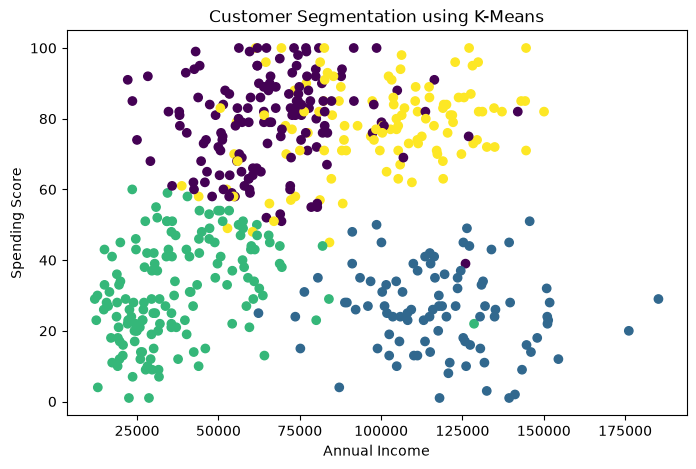

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Example: load your customer dataset
df = pd.read_csv("customers.csv")

# Select numerical features
features = [
    "Age",
    "Annual Income",
    "Spending Score"
]

X = df[features].dropna()

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit K-Means
model = KMeans(
    n_clusters=4,
    init="k-means++",
    n_init=10,
    random_state=42
)

labels = model.fit_predict(X_scaled)

# Attach labels to the retained rows
df_clustered = df.loc[X.index].copy()
df_clustered["Cluster"] = labels

# Evaluate
print("Inertia:", model.inertia_)
print(
    "Silhouette Score:",
    silhouette_score(X_scaled, labels)
)

# Understand cluster characteristics
print(
    df_clustered.groupby("Cluster")[features].mean()
)

# Visualize income against spending score
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clustered["Annual Income"],
    df_clustered["Spending Score"],
    c=labels,
    cmap="viridis"
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation using K-Means")
plt.show()
